# Seminar 6 · A simple denoising model

**Deep Generative Models · MIPT / ШАД (YSDA) · 29 October 2026**

Adapted from the previous semester’s score matching and denoising seminar. The original sequence of topics is preserved.

[Part 1 · Score matching](seminar6.ipynb) · [Part 2 · NCSN](ncsn.ipynb) · [Part 3 · Denoising model](denoising_model.ipynb)

**Ready to present:** saved MNIST results and trajectories are included. This is the previous seminar’s heuristic denoising exercise, not a DDPM implementation.

In [9]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, Tensor
from torch.utils.data import DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False,
                     "axes.titlesize": 13, "font.size": 11})
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}; seed: {SEED}")

from pathlib import Path
from torch.nn import functional as F
from torchvision.datasets import MNIST

class BaseModel(nn.Module):
    @property
    def device(self):
        return next(self.parameters()).device


def train_model(model, train_loader, test_loader, epochs, optimizer, device,
                visualize_samples=False, logscale_y=True):
    # Finite DataLoaders: each epoch completes without a manual interruption.
    train_history, test_history = [], []
    for epoch in range(epochs):
        model.train()
        total, count = 0.0, 0
        for batch in train_loader:
            x = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = model.loss(x)["total_loss"]
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
            count += len(x)
        train_history.append(total / count)
        model.eval()
        total, count = 0.0, 0
        with torch.no_grad():
            for batch in test_loader:
                x = batch.to(device)
                total += model.loss(x)["total_loss"].item() * len(x)
                count += len(x)
        test_history.append(total / count)
        if epoch == 0 or (epoch + 1) % max(1, epochs // 5) == 0:
            print(f"Epoch {epoch + 1}/{epochs}: train={train_history[-1]:.5f}, test={test_history[-1]:.5f}")
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(np.arange(1, epochs + 1), train_history, label="Train", color="#2563eb")
    ax.plot(np.arange(1, epochs + 1), test_history, label="Test", color="#e58b29")
    ax.set(xlabel="Epoch", ylabel="Loss", title="Completed training run")
    if logscale_y: ax.set_yscale("log")
    ax.legend(); plt.tight_layout(); plt.show()
    return train_history, test_history


def show_samples(images, title, nrow=10, figsize=(12, 3)):
    from torchvision.utils import make_grid
    grid = make_grid(torch.as_tensor(images).detach().cpu(), nrow=nrow, padding=2, pad_value=1)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(grid.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()


Device: cpu; seed: 42


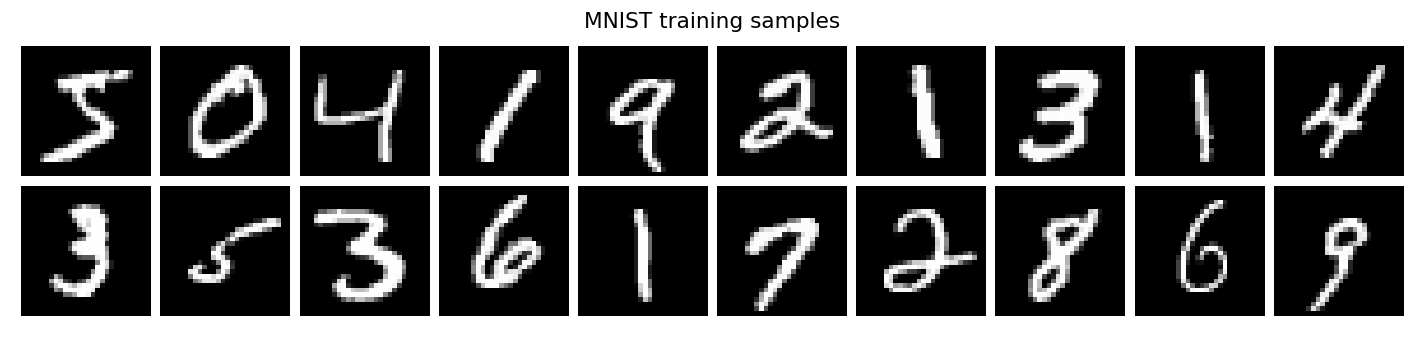

In [10]:
# Reuse a local course MNIST cache when available; otherwise download it once.
cwd = Path.cwd()
candidates = [cwd, *cwd.parents]
roots = [p / "seminars/seminar1" for p in candidates] + [cwd / "data"]
data_root = next((p for p in roots if (p / "MNIST/raw/train-images-idx3-ubyte").is_file()), roots[-1])
train_data = MNIST(root=data_root, train=True, download=True)
test_data = MNIST(root=data_root, train=False, download=True)
trainset = train_data.data.float().unsqueeze(1) / 255
testset = test_data.data.float().unsqueeze(1) / 255
show_samples(trainset[:20], title="MNIST training samples", nrow=10, figsize=(12, 3))


## From score prediction to clean-image prediction

NCSN predicts a score. What if a network directly predicts the clean image from its corrupted version? We keep the original exercise: predict, add a smaller amount of noise, and repeat.

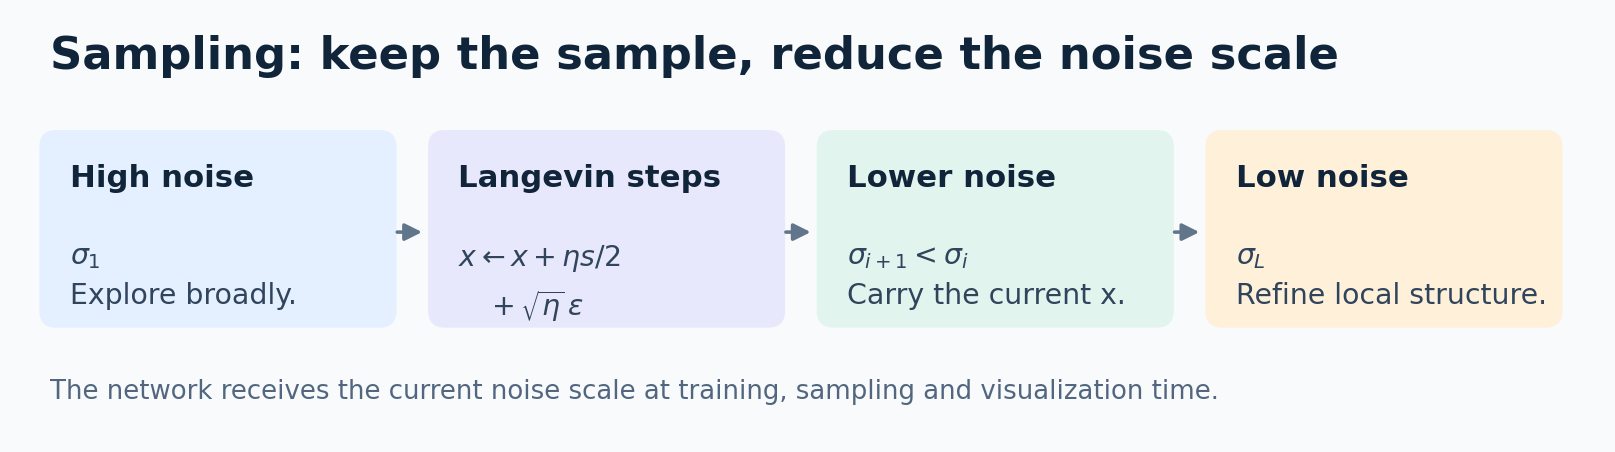

**Distinction:** the following re-corruption loop is a heuristic; it is not the Langevin update shown above.

### Corruption and its target

This exercise uses **uniform** noise $u\sim\mathcal{U}([0,1]^D)$, matching the original corruption code:
$$y_a=(1-a)x+a u,\qquad a\in[0,1].$$
At $a=0$ the input is clean; at $a=1$ it is pure uniform noise. Training and sampling must use the same noise distribution.

The predictor estimates the clean image, then a smaller amount of fresh uniform noise is mixed in. This is an illustrative denoising loop, not an exact reverse process.

## The small U-Net

We retain the original convolutional encoder/decoder and its additive skip connections. The general architecture is inspired by [U-Net (Ronneberger et al., 2015)](https://arxiv.org/abs/1505.04597).

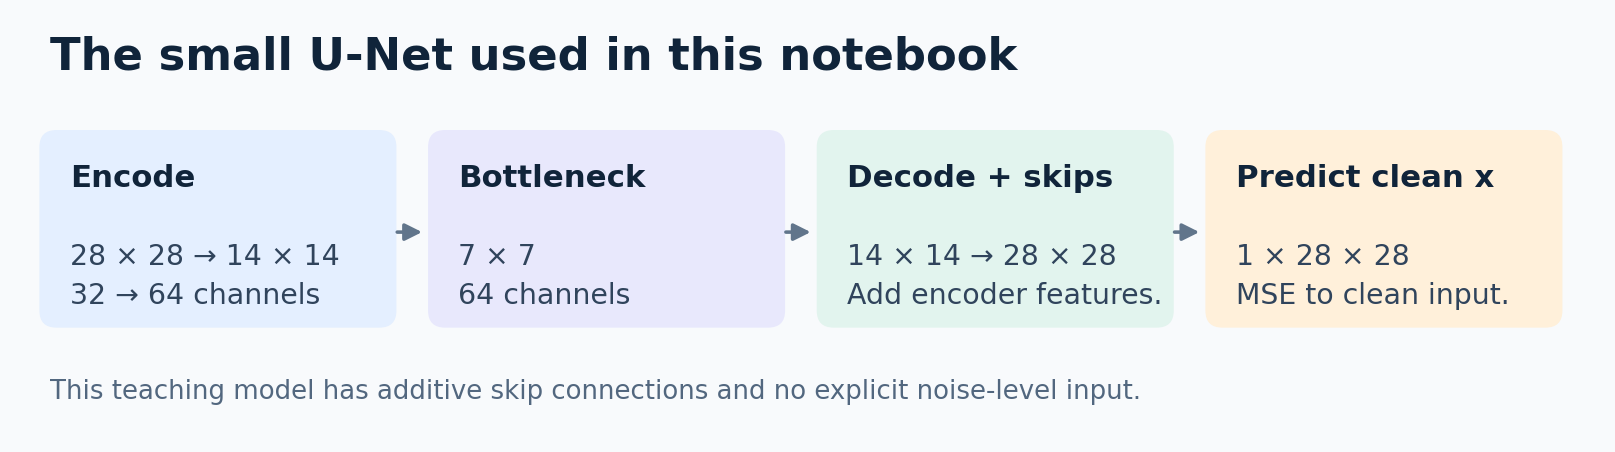

In [3]:
class BasicUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        self.down_layers = nn.ModuleList([ 
            nn.Conv2d(in_channels, 32, kernel_size=5, padding=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.Conv2d(64, 64, kernel_size=5, padding=2),
        ])
        self.up_layers = nn.ModuleList([
            nn.Conv2d(64, 64, kernel_size=5, padding=2),
            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.Conv2d(32, out_channels, kernel_size=5, padding=2), 
        ])
        self.act = nn.SiLU() # The activation function
        self.downscale = nn.MaxPool2d(2)
        self.upscale = nn.Upsample(scale_factor=2)

    def forward(self, x):
        h = []
        for i, l in enumerate(self.down_layers):
            x = self.act(l(x)) # Through the layer and the activation function
            if i < 2: # For all but the third (final) down layer:
              h.append(x) # Storing output for skip connection
              x = self.downscale(x) # Downscale ready for the next layer
              
        for i, l in enumerate(self.up_layers):
            if i > 0: # For all except the first up layer
              x = self.upscale(x) # Upscale
              x += h.pop() # Fetching stored output (skip connection)
            x = self.act(l(x)) # Through the layer and the activation function
            
        return x

## Noise amount

Each training image receives its own corruption amount. Increasing it makes the input less informative. This model is **not explicitly conditioned on the amount**; that is a deliberate limitation of the original exercise.

### Training

Sample $x$, an amount $a\sim\mathcal{U}(0,1)$ and uniform noise $u$. Predict $\hat x=f_\theta((1-a)x+au)$ and minimize
$$\mathcal{L}=\mathbb{E}\|f_\theta(y_a)-x\|^2.$$

**Takeaway.** Under squared error, the ideal predictor is a conditional mean. At high corruption it can average different plausible digits, giving blurry outputs.

In [4]:
class DenoisingNet(BaseModel):
    def __init__(self, input_shape=(1, 28, 28)):
        super().__init__()
        self.input_shape = input_shape

        self.model = BasicUNet(
            in_channels=input_shape[0], 
            out_channels=input_shape[0]
        )

    @staticmethod
    def perturbe(x: torch.Tensor, amount: torch.Tensor, device: str = "cpu"):
        noise = torch.rand_like(x)
        amount = torch.as_tensor(amount, device=x.device, dtype=x.dtype).reshape(-1, 1, 1, 1)
        return (1 - amount) * x + noise * amount

    def forward(self, x):
        amount = torch.rand(x.shape[0], device=self.device)
        x_noisy = DenoisingNet.perturbe(x, amount, self.device)
        return F.mse_loss(x, self.model(x_noisy))
    
    def loss(self, x: torch.Tensor):
        return {"total_loss": self(x).mean(dim=0).sum()}
    
    @torch.no_grad()
    def sample(self, n: int, num_steps: int = 10, return_trajs: bool = False):
        assert num_steps >= 2
        noise = torch.rand(n, *self.input_shape, device=self.device)
        x_clean = self.model(noise)
        if return_trajs:
            traj = [noise.clip(0, 1).cpu()]
            guesses = [x_clean.clip(0, 1).cpu()]
        
        for i in reversed(range(num_steps - 1)):
            amount = torch.tensor([i / (num_steps - 1)] * n).to(self.device)
            x_noisy = DenoisingNet.perturbe(x_clean, amount, self.device)
            x_clean = self.model(x_noisy)
            if return_trajs:
                traj.append(x_noisy.clip(0, 1).cpu())
                guesses.append(x_clean.clip(0, 1).cpu())

        if return_trajs:
            return guesses, traj
        return x_clean.clip(0, 1)


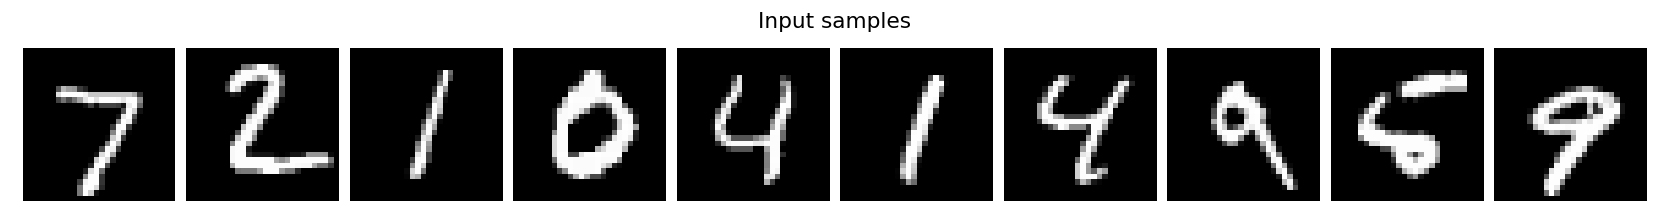

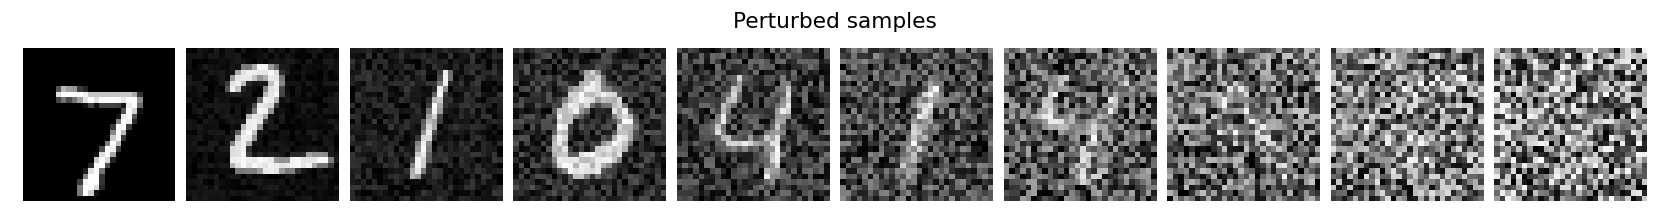

In [5]:
samples_to_perturbe = testset[:10].clone()
show_samples(samples_to_perturbe, title='Input samples', nrow=10, figsize=(20, 2))
amount = torch.linspace(0, 1, 10)

perturbed_samples = DenoisingNet.perturbe(samples_to_perturbe, amount)
show_samples(perturbed_samples, title='Perturbed samples', nrow=10, figsize=(20, 2))

As noise amount approaches one, our data begins to look like pure random noise. But for most noise amounts, you can guess the digit fairly well.

Epoch 1/3: train=0.03069, test=0.02404
Epoch 2/3: train=0.02363, test=0.02189
Epoch 3/3: train=0.02155, test=0.02129


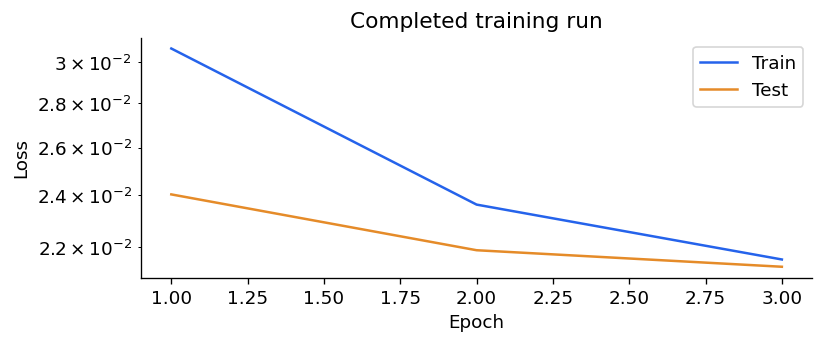

Epoch 3/3: train=0.02155, test=0.02129


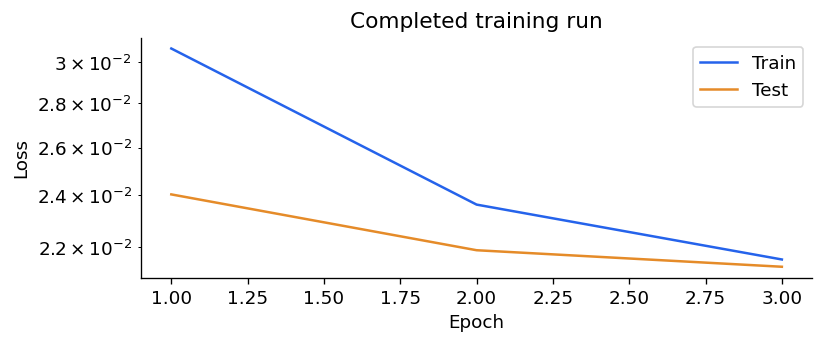

In [6]:
# Demonstration budget: 20,000 training images, 2,000 test images, 3 complete epochs.
model = DenoisingNet().to(device)

train_loader = DataLoader(trainset[:20000], batch_size=128, shuffle=True)
test_loader = DataLoader(testset[:2000], batch_size=128, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

denoising_history = train_model(
    model,
    train_loader,
    test_loader,
    epochs=3,
    optimizer=optimizer,
    device=device,
    visualize_samples=False,
    logscale_y=True,
)

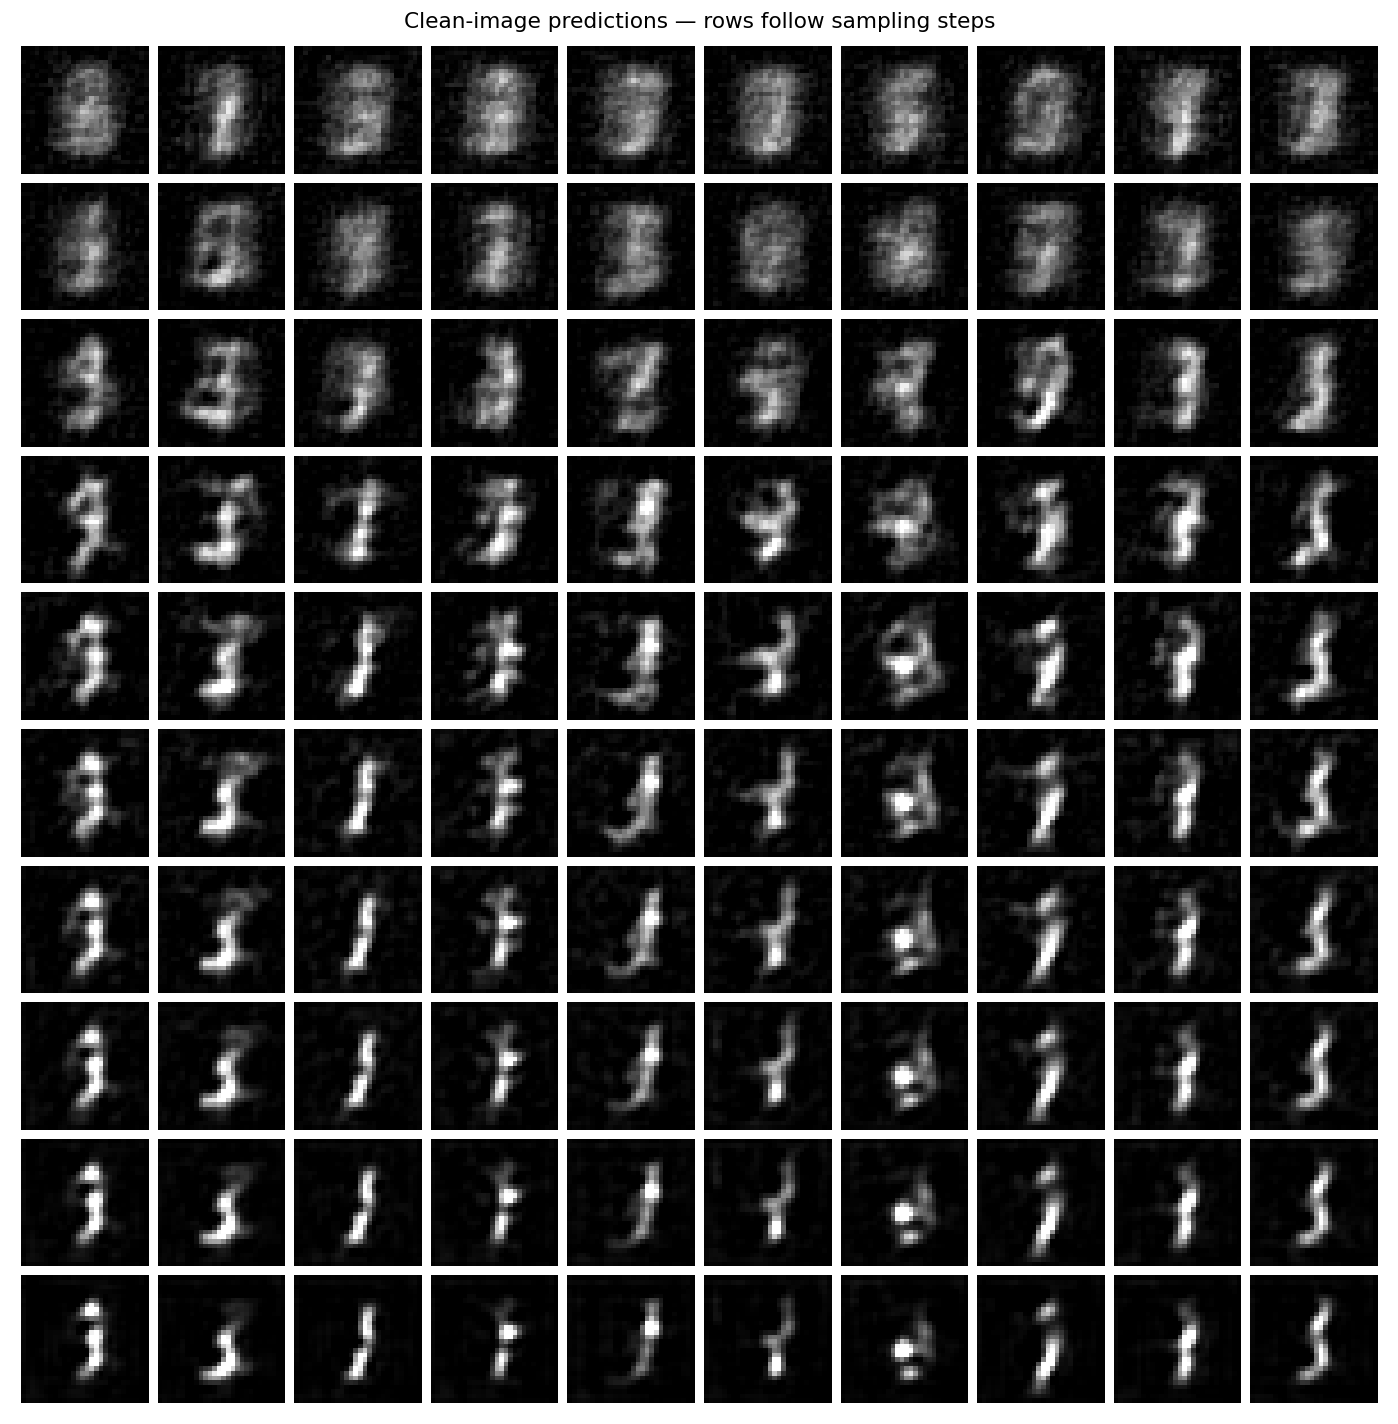

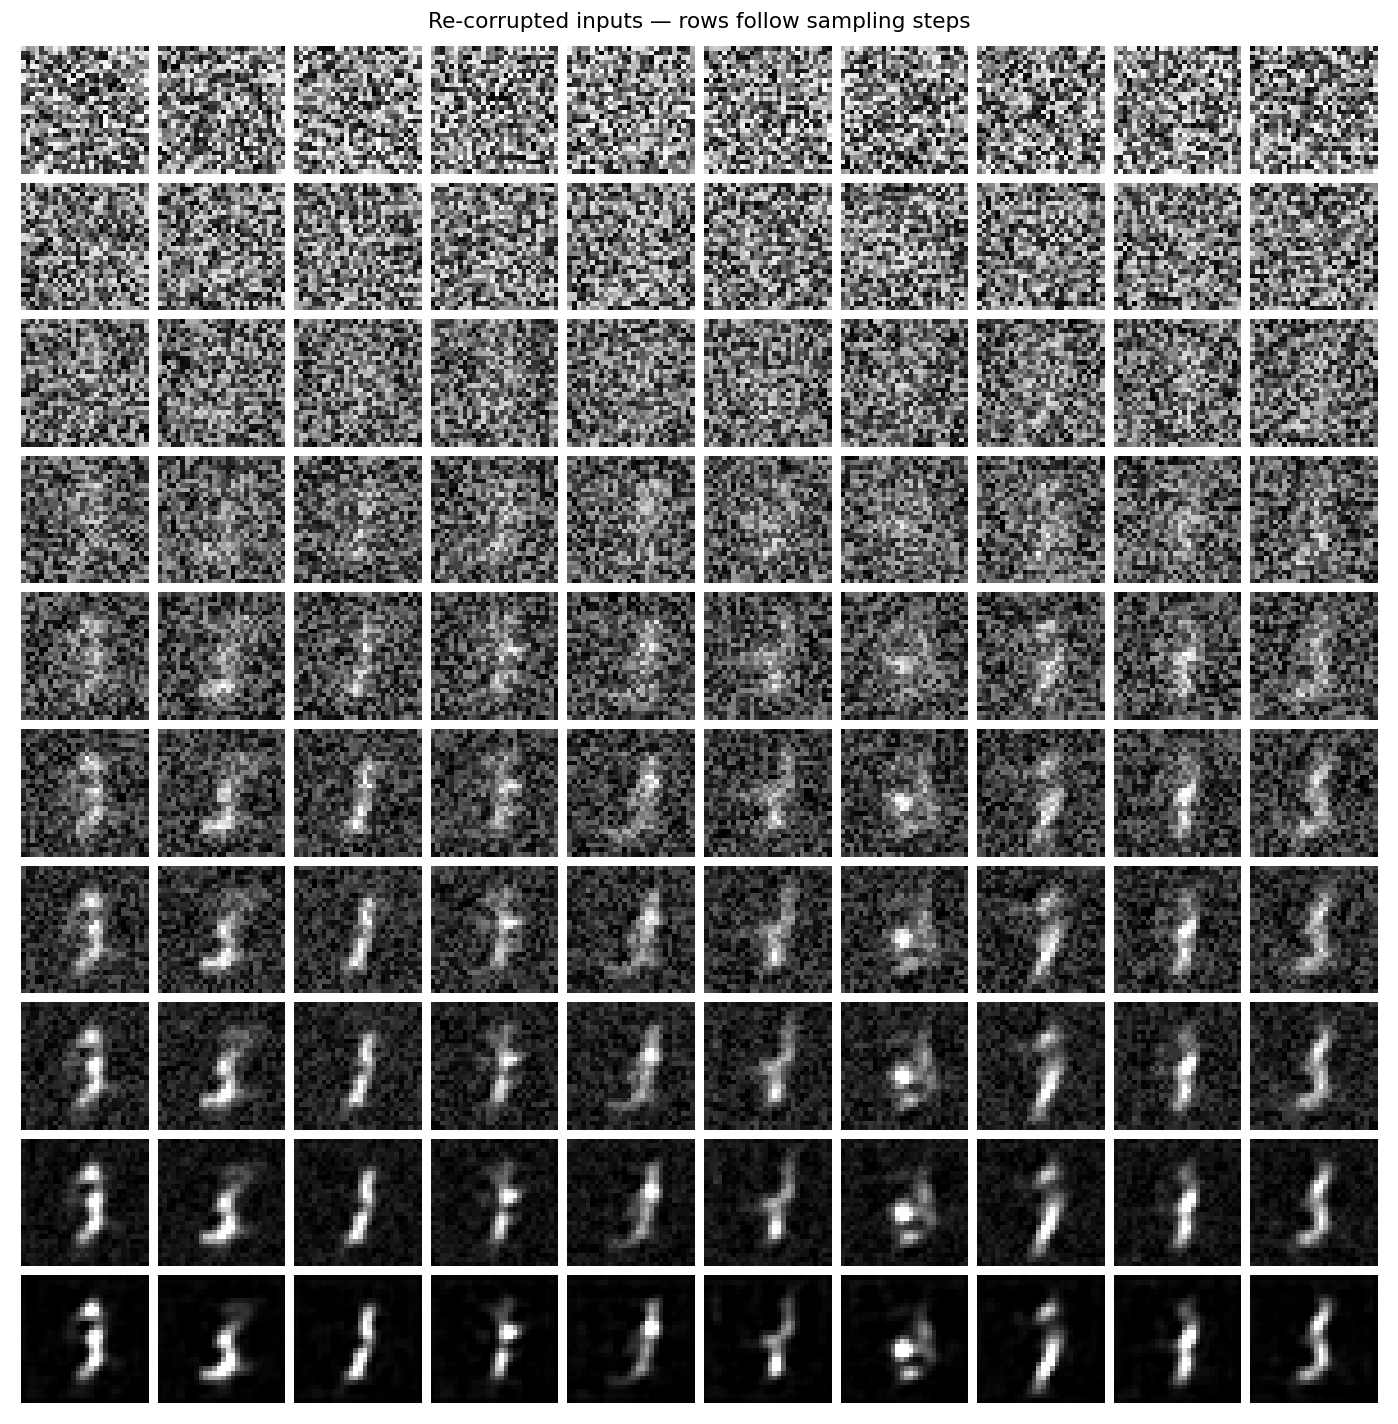

In [7]:
guesses, traj = model.sample(10, return_trajs=True)
guesses = torch.stack(guesses, dim=0).reshape(-1, 1, 28, 28).cpu()
traj = torch.stack(traj, dim=0).reshape(-1, 1, 28, 28).cpu()

show_samples(guesses, title='Clean-image predictions — rows follow sampling steps', nrow=10, figsize=(12, 12))
show_samples(traj, title='Re-corrupted inputs — rows follow sampling steps', nrow=10, figsize=(12, 12))

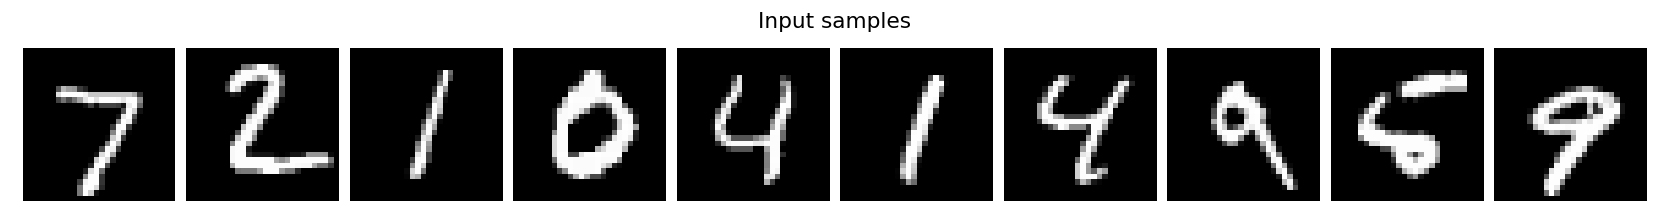

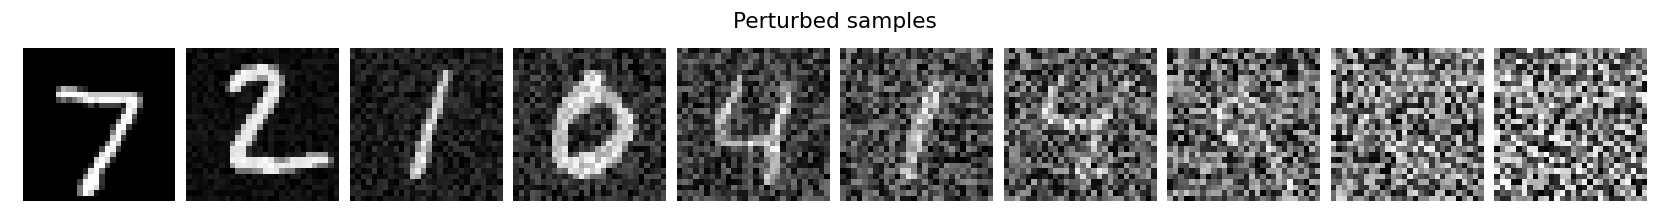

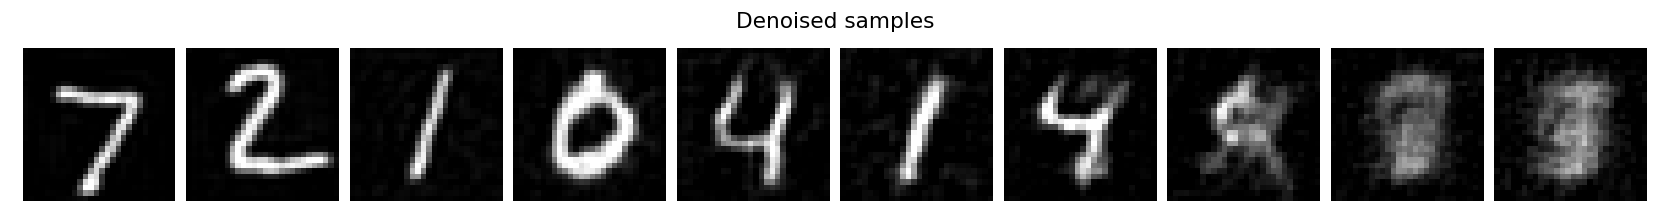

In [8]:
samples_to_perturbe = testset[:10].clone()
show_samples(samples_to_perturbe, title='Input samples', nrow=10, figsize=(20, 2))
amount = torch.linspace(0, 1, 10)

perturbed_samples = DenoisingNet.perturbe(samples_to_perturbe, amount)
show_samples(perturbed_samples, title='Perturbed samples', nrow=10, figsize=(20, 2))

with torch.no_grad():
    denoised_samples = model.model(perturbed_samples.to(device)).cpu().clip(0, 1)
show_samples(denoised_samples, title='Denoised samples', nrow=10, figsize=(20, 2))

## Takeaways

1. A denoiser can learn reconstruction without a discriminator.
2. At high corruption, MSE prediction tends to average plausible explanations.
3. A denoising network alone does not define a principled generative sampler.
4. This exercise uses uniform corruption and no explicit time conditioning; it is not the Gaussian score model of Parts 1–2.

**Closing question:** what is missing between a useful denoiser and a justified diffusion sampling algorithm?